# Projekt: Gun Detector — Detekcja broni na zdjęciach

**Cel:** Zbudowanie detektora broni krótkiej i długiej na zdjęciach z użyciem modelu YOLOv8 (fine-tuning).

**Dataset:** Weapon-2 z Roboflow Universe (CC BY 4.0)
- 2 klasy: `guns`, `knife`
- Format: YOLO (bounding boxes)

**Model:** YOLOv8n (nano) — fine-tuning z pretrenowanych wag na 25 epokach

In [1]:
!pip install -q ultralytics opencv-python-headless matplotlib Pillow requests pyyaml


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import glob
import random
import yaml
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from ultralytics import YOLO
import torch
import warnings
warnings.filterwarnings('ignore')

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device: {device}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

Device: cuda
PyTorch: 2.6.0+cu124
CUDA available: True


## 1. Konfiguracja datasetu

Eksploracja struktury datasetu, `data.yaml`, przykładowe anotacje i wizualizacja próbek treningowych z bounding boxami.


In [3]:
DATA_DIR = 'data'
YAML_PATH = os.path.join(DATA_DIR, 'data.yaml')

with open(YAML_PATH) as f:
    data_config = yaml.safe_load(f)

print("=== data.yaml ===")
for k, v in data_config.items():
    print(f"  {k}: {v}")

train_images = sorted(glob.glob(os.path.join(DATA_DIR, 'train', 'images', '*.jpg')))
test_images = sorted(glob.glob(os.path.join(DATA_DIR, 'test', 'images', '*.jpg')))
train_labels = sorted(glob.glob(os.path.join(DATA_DIR, 'train', 'labels', '*.txt')))
test_labels = sorted(glob.glob(os.path.join(DATA_DIR, 'test', 'labels', '*.txt')))

print(f"\nStruktura datasetu:")
print(f"  Train: {len(train_images)} obrazów, {len(train_labels)} etykiet")
print(f"  Test:  {len(test_images)} obrazów, {len(test_labels)} etykiet")
print(f"\nKlasy ({data_config['nc']}): {data_config['names']}")

print(f"\nPrzykładowa etykieta:")
sample_label = train_labels[0]
print(f"  Plik: {os.path.basename(sample_label)}")
with open(sample_label) as f:
    print(f"  Zawartość: {f.read().strip()}")

=== data.yaml ===
  train: train/images
  val: test/images
  test: test/images
  nc: 2
  names: ['guns', 'knife']
  roboflow: {'workspace': 'joao-assalim-xmovq', 'project': 'weapon-2', 'version': 2, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/joao-assalim-xmovq/weapon-2/dataset/2'}

Struktura datasetu:
  Train: 3839 obrazów, 3839 etykiet
  Test:  259 obrazów, 259 etykiet

Klasy (2): ['guns', 'knife']

Przykładowa etykieta:
  Plik: Dikran_Tulaine-B92F_jpg.rf.9964ecb6403877b3743b521ca5c0953e.txt
  Zawartość: 0 0.490625 0.28984375 0.1515625 0.1609375


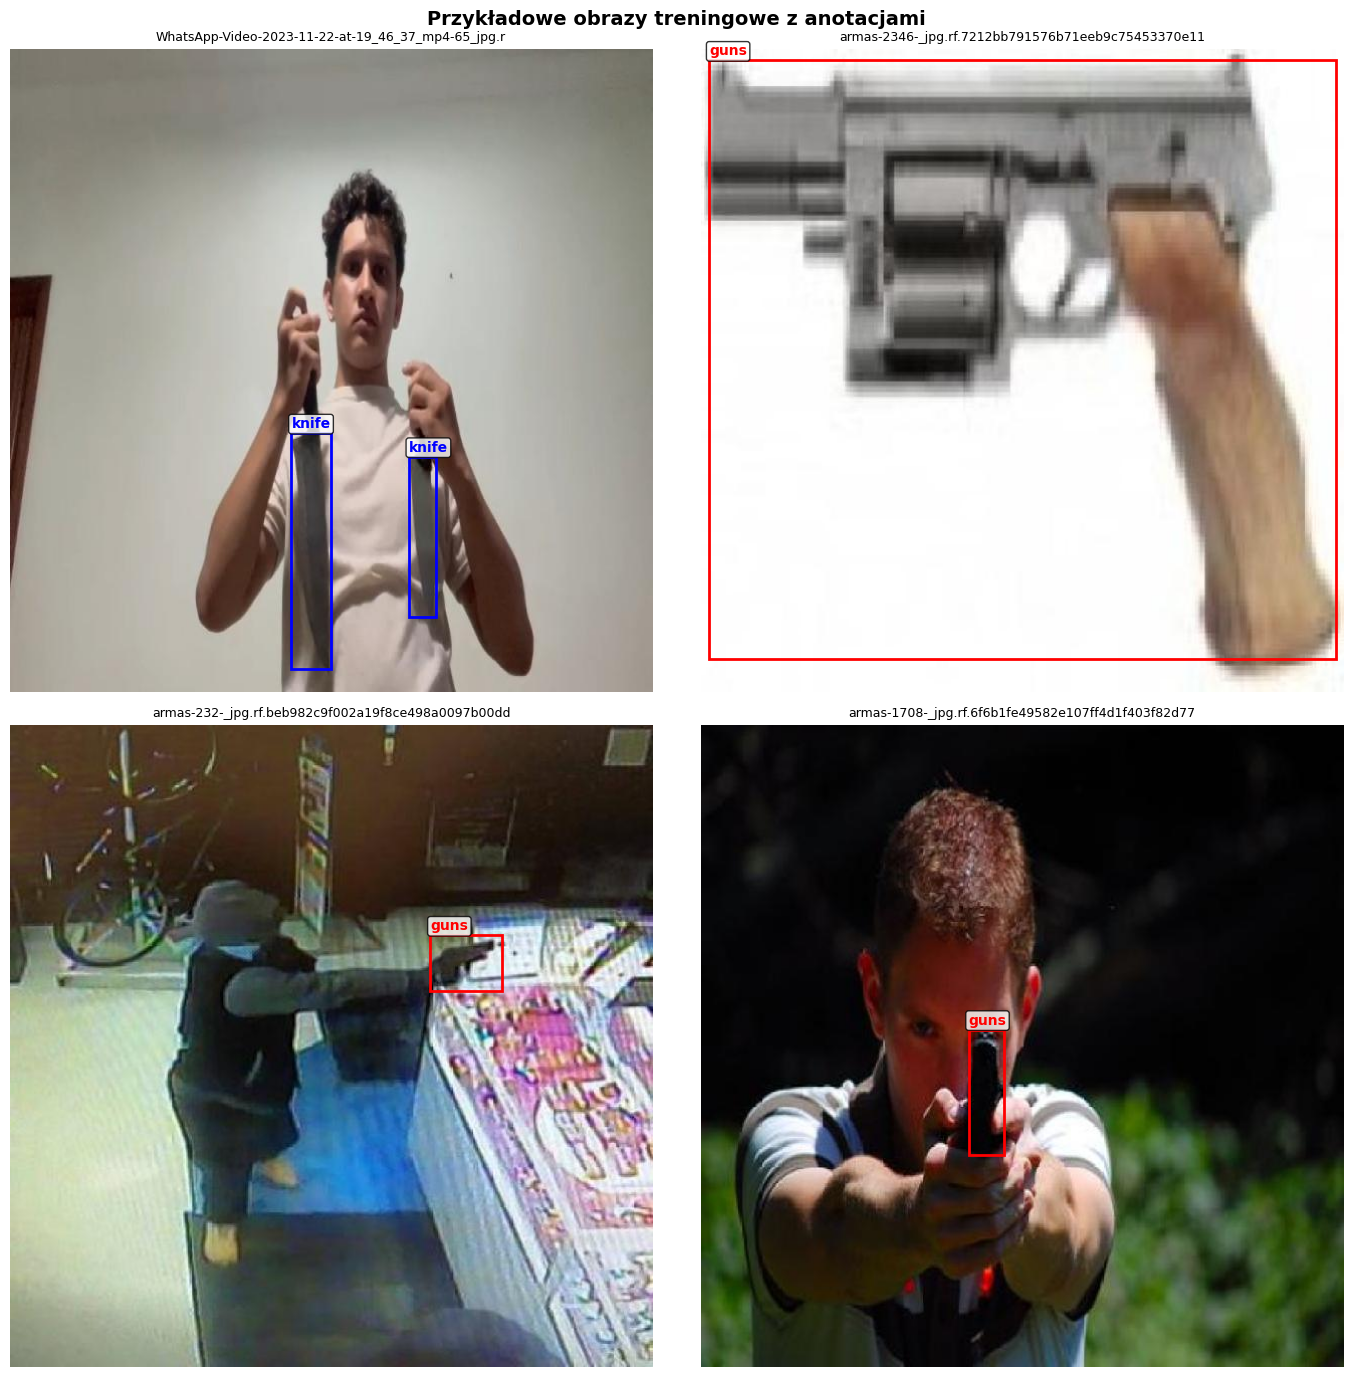

In [4]:
CLASS_NAMES = data_config['names']
COLORS = ['red', 'blue']

fig, axes = plt.subplots(2, 2, figsize=(14, 14))
axes = axes.flatten()

sample_indices = random.sample(range(len(train_images)), min(4, len(train_images)))

for i, idx in enumerate(sample_indices):
    img_path = train_images[idx]
    img = Image.open(img_path)
    w, h = img.size
    axes[i].imshow(img)

    label_path = img_path.replace('images', 'labels').replace('.jpg', '.txt')
    if os.path.exists(label_path):
        with open(label_path) as f:
            for line in f:
                parts = line.strip().split()
                cls_id = int(parts[0])
                cx, cy, bw, bh = float(parts[1]), float(parts[2]), float(parts[3]), float(parts[4])
                x1 = (cx - bw / 2) * w
                y1 = (cy - bh / 2) * h
                rect = patches.Rectangle(
                    (x1, y1), bw * w, bh * h, linewidth=2,
                    edgecolor=COLORS[cls_id % len(COLORS)], facecolor='none'
                )
                axes[i].add_patch(rect)
                axes[i].text(
                    x1, y1 - 5, CLASS_NAMES[cls_id],
                    color=COLORS[cls_id % len(COLORS)], fontsize=10, fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8)
                )

    axes[i].set_title(os.path.basename(img_path)[:50], fontsize=9)
    axes[i].axis('off')

plt.suptitle('Przykładowe obrazy treningowe z anotacjami', fontsize=14, fontweight='bold')
plt.tight_layout()
os.makedirs('images', exist_ok=True)
plt.savefig('images/01_dataset_config.png', dpi=150, bbox_inches='tight')
plt.show()

Rozkład klas w zbiorze treningowym:
  guns: 2066 obiektów
  knife: 2524 obiektów


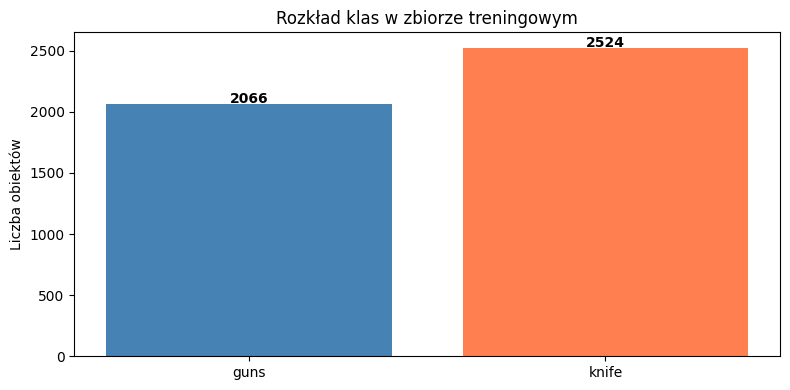

In [5]:
class_counts = {name: 0 for name in CLASS_NAMES}
for label_file in train_labels:
    with open(label_file) as f:
        for line in f:
            cls_id = int(line.strip().split()[0])
            if cls_id < len(CLASS_NAMES):
                class_counts[CLASS_NAMES[cls_id]] += 1

print("Rozkład klas w zbiorze treningowym:")
for name, count in class_counts.items():
    print(f"  {name}: {count} obiektów")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(class_counts.keys(), class_counts.values(), color=['steelblue', 'coral'])
ax.set_ylabel('Liczba obiektów')
ax.set_title('Rozkład klas w zbiorze treningowym')
for i, (name, count) in enumerate(class_counts.items()):
    ax.text(i, count + 5, str(count), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

## 2. Trening modelu YOLOv8

Fine-tuning modelu YOLOv8n (nano) na datasecie Weapon-2. Minimum 25 epok, z zapisem najlepszego modelu (`best.pt`).


In [6]:
model = YOLO('yolov8n.pt')

results = model.train(
    data=YAML_PATH,
    epochs=25,
    imgsz=640,
    batch=16,
    name='weapon_detector',
    patience=10,
    save=True,
    plots=True,
    verbose=True
)

New https://pypi.org/project/ultralytics/8.4.38 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.14  Python-3.12.6 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data\data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=weapon_

2026/04/17 08:59:18 INFO mlflow.tracking.fluent: Experiment with name '/Shared/Ultralytics' does not exist. Creating a new experiment.


MLflow: logging run_id(ff1b8f6c05ff490594cfe2246c4077eb) to runs\mlflow
MLflow: view at http://127.0.0.1:5000 with 'mlflow server --backend-store-uri runs\mlflow'
MLflow: disable with 'yolo settings mlflow=False'
Image sizes 640 train, 640 val
Using 8 dataloader workers
Logging results to C:\github\glebokie-uczenie-praca-zal\weapon-detector-notebook\runs\detect\weapon_detector
Starting training for 25 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/25         2G      1.231      2.266      1.456         40        640: 100% ━━━━━━━━━━━━ 240/240 5.1it/s 47.0s<0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 4.5it/s 2.0s0.2s
                   all        259        481      0.808      0.369      0.387      0.253

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/25      2.32G        1.3      1.785      1.507         33        640: 100% ━

Katalog wyników: runs/detect\weapon_detector\


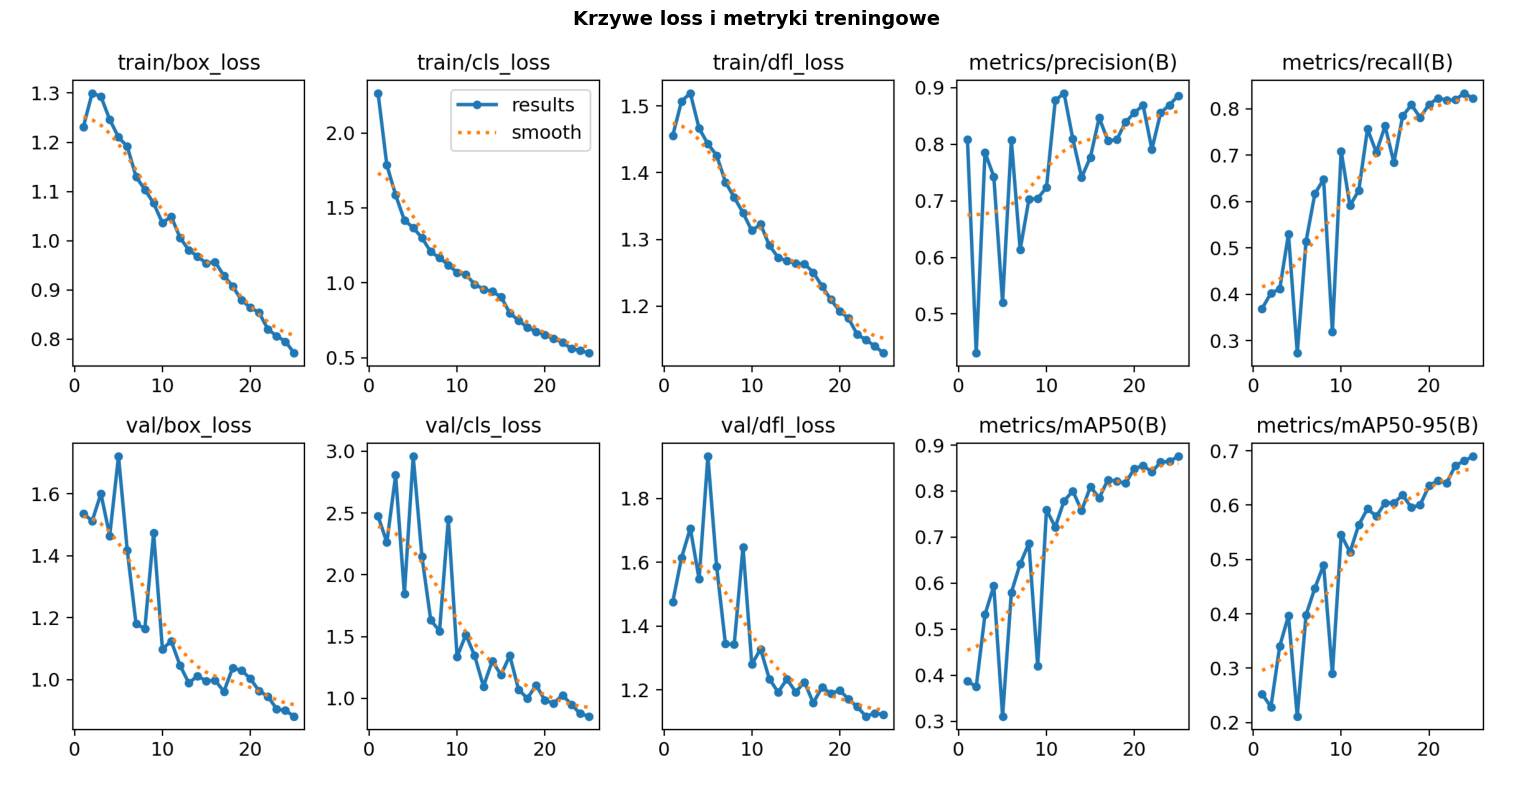

In [7]:
results_dirs = sorted(glob.glob('runs/detect/weapon_detector*/'))
latest_run = results_dirs[-1] if results_dirs else 'runs/detect/weapon_detector/'
print(f"Katalog wyników: {latest_run}")

results_img = os.path.join(latest_run, 'results.png')
if os.path.exists(results_img):
    img = Image.open(results_img)
    plt.figure(figsize=(18, 8))
    plt.imshow(img)
    plt.axis('off')
    plt.title('Krzywe loss i metryki treningowe', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('images/02_training_results.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print(f"Nie znaleziono results.png w {latest_run}")

## 3. Ewaluacja modelu

Ocena najlepszego modelu na zbiorze testowym/walidacyjnym. Wyświetlenie metryk mAP50, mAP50-95, Precision, Recall oraz Confusion Matrix.


In [8]:
best_model_path = os.path.join(latest_run, 'weights', 'best.pt')
print(f"Ładowanie najlepszego modelu: {best_model_path}")

model_best = YOLO(best_model_path)
val_results = model_best.val(data=YAML_PATH, verbose=True)

print(f"\n{'='*50}")
print(f"WYNIKI EWALUACJI")
print(f"{'='*50}")
print(f"mAP50:     {val_results.box.map50:.4f}")
print(f"mAP50-95:  {val_results.box.map:.4f}")
print(f"Precision: {val_results.box.mp:.4f}")
print(f"Recall:    {val_results.box.mr:.4f}")

Ładowanie najlepszego modelu: runs/detect\weapon_detector\weights\best.pt
Ultralytics 8.4.14  Python-3.12.6 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
Model summary (fused): 73 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 76.332.5 MB/s, size: 26.3 KB)
val: Scanning C:\github\glebokie-uczenie-praca-zal\weapon-detector-notebook\data\test\labels.cache... 259 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 259/259  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 4.7it/s 3.6s0.1s
                   all        259        481      0.887      0.822      0.875       0.69
                  guns        161        306      0.868       0.65      0.776      0.588
                 knife         93        175      0.905      0.994      0.974      0.793
Speed: 2.6ms preprocess, 4.6ms inference, 0.0ms loss, 2.0ms postprocess per image
Results sav

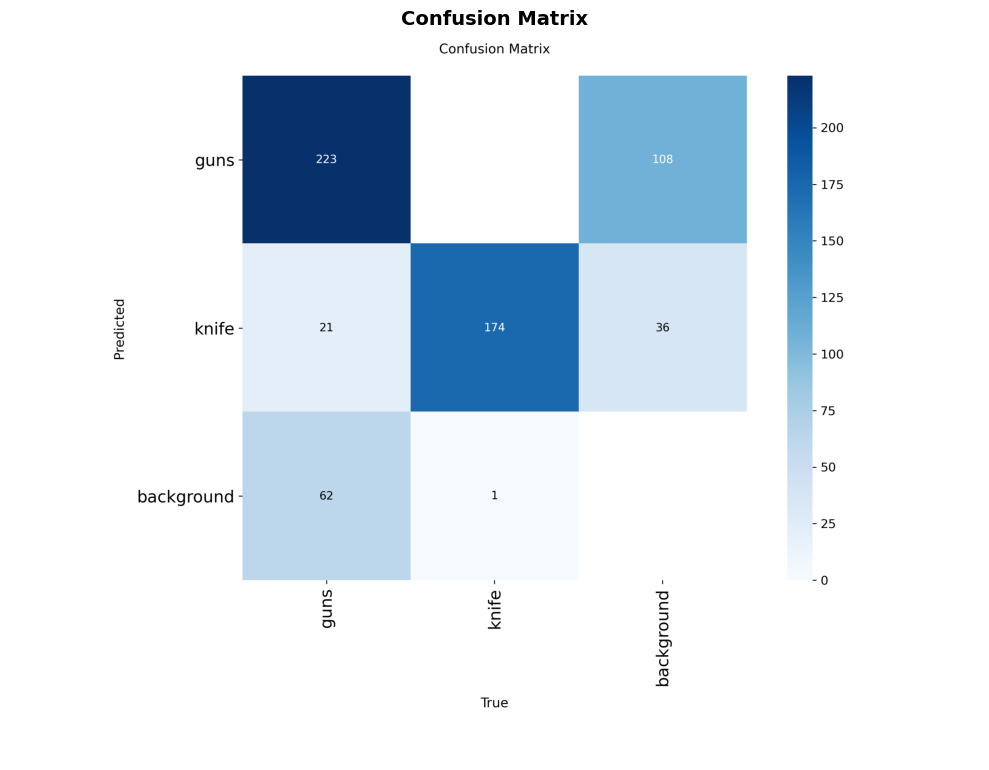

In [9]:
confusion_matrix_img = os.path.join(latest_run, 'confusion_matrix.png')
if os.path.exists(confusion_matrix_img):
    img = Image.open(confusion_matrix_img)
    plt.figure(figsize=(10, 8))
    plt.imshow(img)
    plt.axis('off')
    plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('images/03_evaluation.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print(f"Nie znaleziono confusion_matrix.png w {latest_run}")

## 4. Inferencja na nowych zdjęciach

Test modelu na zdjęciach z broni (ze zbioru testowego) oraz zdjęciach **bez broni** (pobrane z internetu) — weryfikacja czy model poprawnie odróżnia broń od nie-broni.


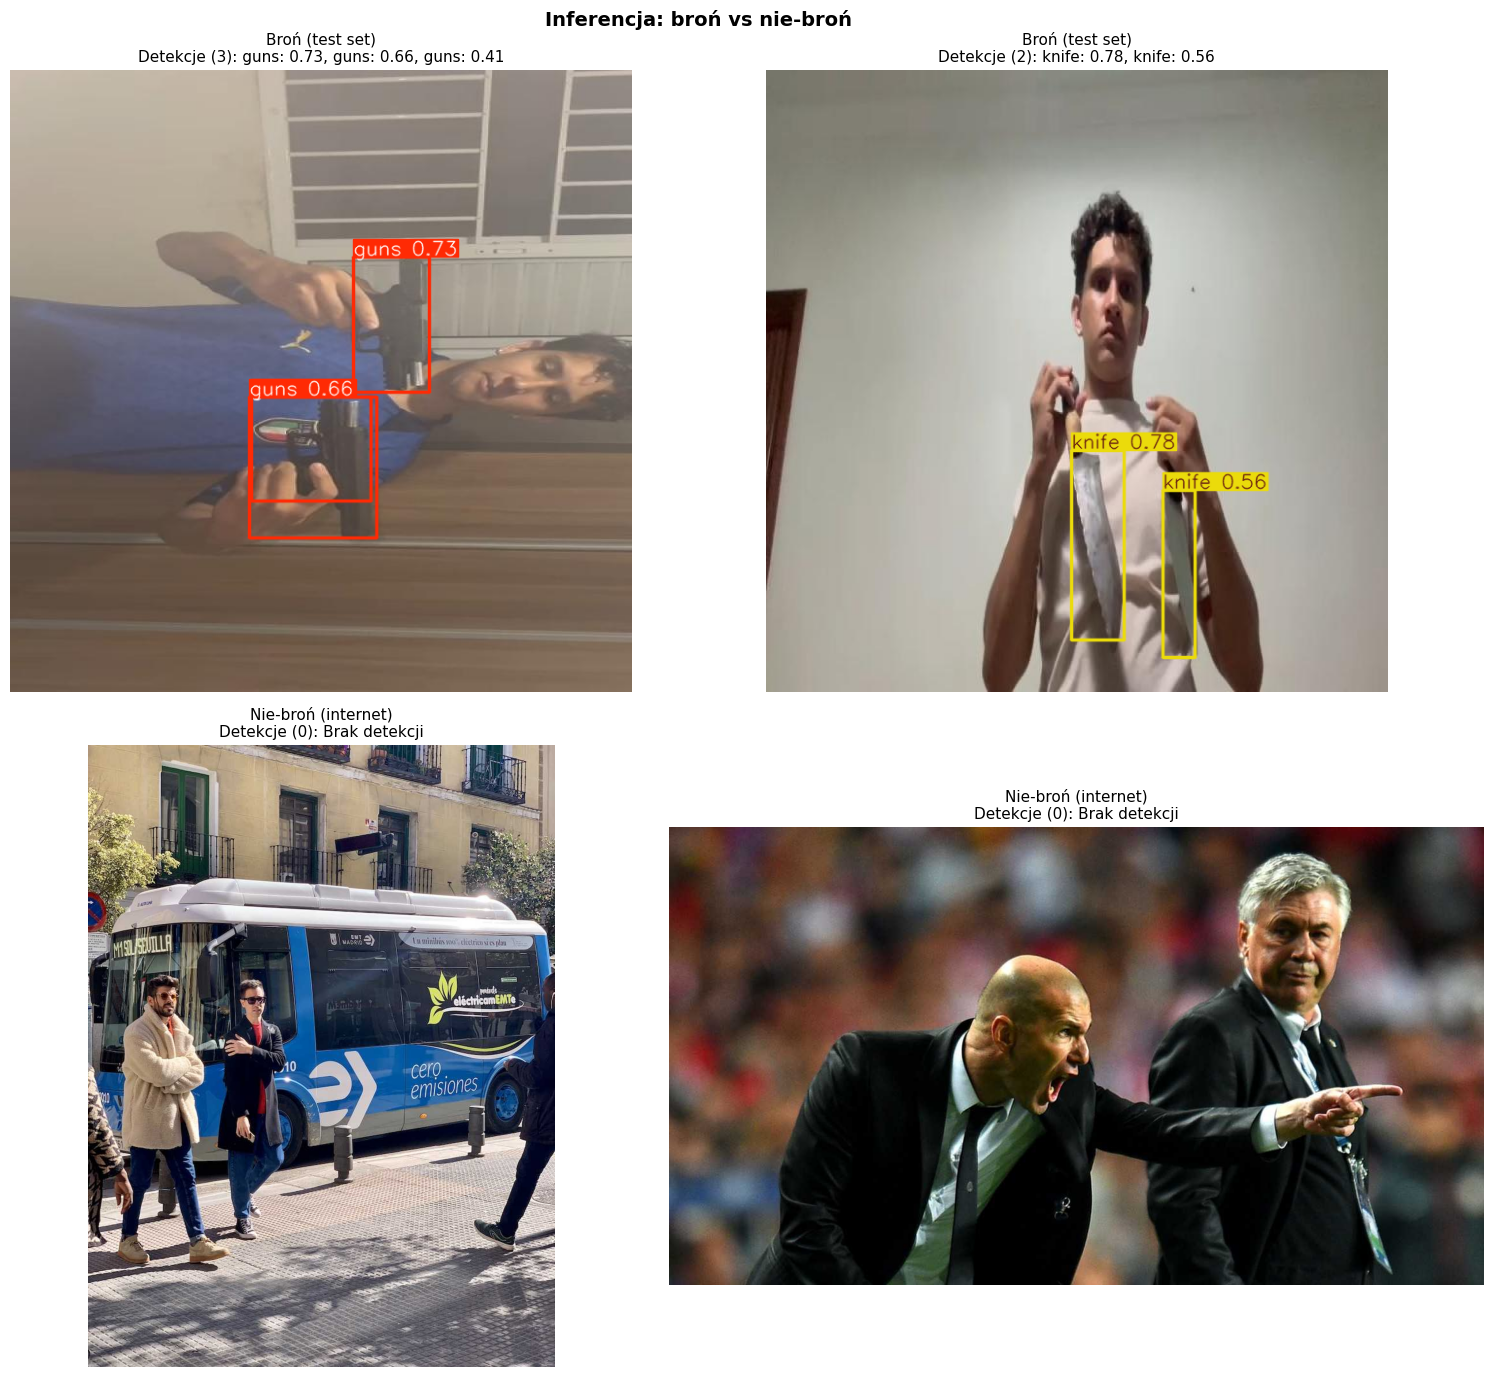

In [10]:
import requests
from io import BytesIO

def load_image_from_url(url):
    response = requests.get(url, timeout=10)
    return Image.open(BytesIO(response.content)).convert('RGB')

# 2 zdjęcia z broni (z test set) + 2 zdjęcia bez broni (z internetu)
test_weapon_imgs = random.sample(test_images, min(2, len(test_images)))

non_weapon_urls = [
    "https://ultralytics.com/images/bus.jpg",
    "https://ultralytics.com/images/zidane.jpg",
]

all_test = []
all_titles = []

for img_path in test_weapon_imgs:
    all_test.append(np.array(Image.open(img_path)))
    all_titles.append("Broń (test set)")

for url in non_weapon_urls:
    try:
        img = load_image_from_url(url)
        all_test.append(np.array(img))
        all_titles.append("Nie-broń (internet)")
    except Exception as e:
        print(f"Nie udało się pobrać: {url} - {e}")

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.flatten()

for i, (img_array, title) in enumerate(zip(all_test, all_titles)):
    if i >= 4:
        break
    det_results = model_best.predict(img_array, conf=0.25, verbose=False)
    annotated = det_results[0].plot()
    axes[i].imshow(annotated)

    num_det = len(det_results[0].boxes)
    det_info = []
    for box in det_results[0].boxes:
        cls_name = model_best.names[int(box.cls[0])]
        conf = box.conf[0].item()
        det_info.append(f"{cls_name}: {conf:.2f}")
    det_text = ", ".join(det_info) if det_info else "Brak detekcji"
    axes[i].set_title(f"{title}\nDetekcje ({num_det}): {det_text}", fontsize=11)
    axes[i].axis('off')

for j in range(len(all_test), 4):
    axes[j].axis('off')

plt.suptitle('Inferencja: broń vs nie-broń', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('images/04_inference.png', dpi=150, bbox_inches='tight')
plt.show()

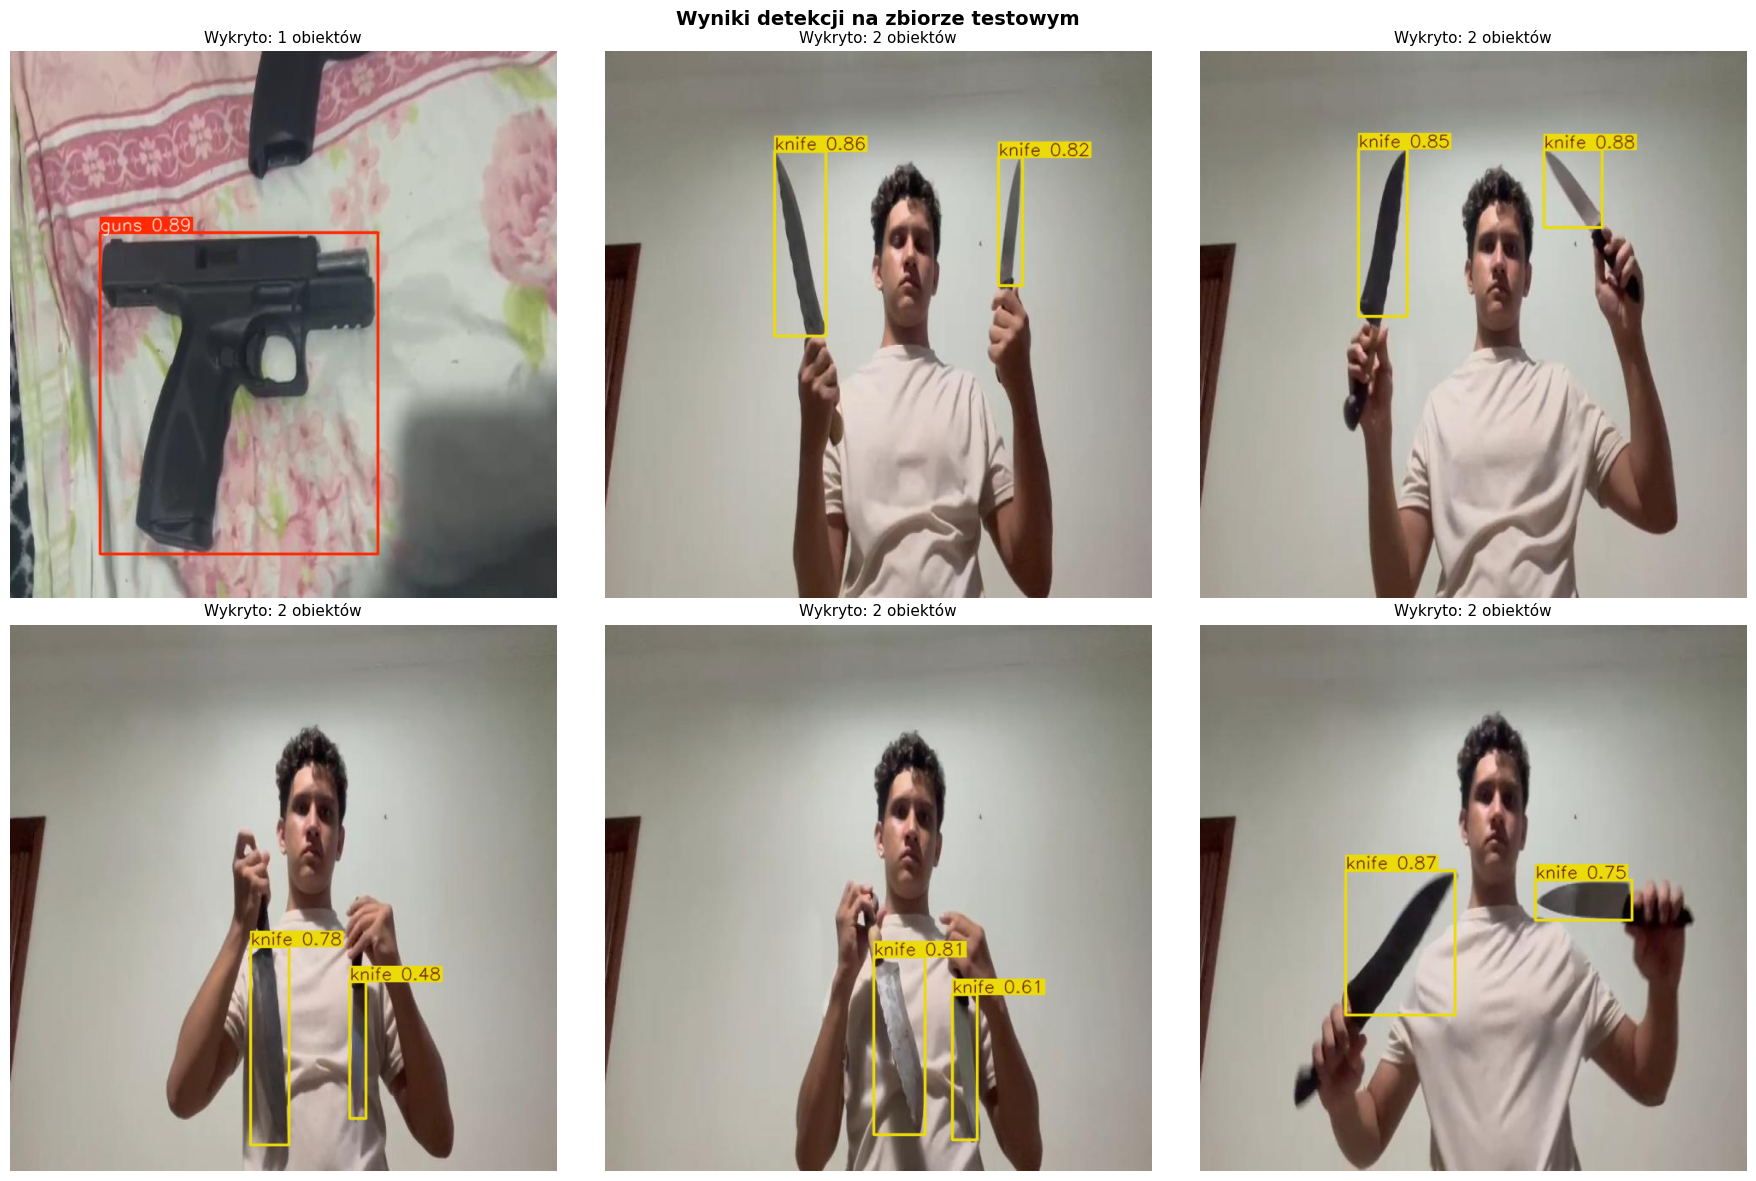

In [19]:
n_test = min(6, len(test_images))
test_sample = random.sample(test_images, n_test)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, img_path in enumerate(test_sample):
    img_array = np.array(Image.open(img_path))
    det_results = model_best.predict(img_array, conf=0.25, verbose=False)
    annotated = det_results[0].plot()
    axes[i].imshow(annotated)
    n_det = len(det_results[0].boxes)
    axes[i].set_title(f"Wykryto: {n_det} obiektów", fontsize=11)
    axes[i].axis('off')

for j in range(n_test, len(axes)):
    axes[j].axis('off')

plt.suptitle('Wyniki detekcji na zbiorze testowym', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Podsumowanie

Model YOLOv8n został wytrenowany na datasecie Weapon-2 (Roboflow) do detekcji broni (`guns`) i noży (`knife`). Poniżej podsumowanie wyników.

In [20]:
print("=" * 60)
print("PODSUMOWANIE PROJEKTU: Gun Detector")
print("=" * 60)
print(f"Model:       YOLOv8n (fine-tuned)")
print(f"Dataset:     Weapon-2 (Roboflow, CC BY 4.0)")
print(f"Klasy:       {CLASS_NAMES}")
print(f"Train imgs:  {len(train_images)}")
print(f"Test imgs:   {len(test_images)}")
print(f"Epochs:      25")
print(f"mAP50:       {val_results.box.map50:.4f}")
print(f"mAP50-95:    {val_results.box.map:.4f}")
print(f"Precision:   {val_results.box.mp:.4f}")
print(f"Recall:      {val_results.box.mr:.4f}")
print(f"\nBest model:  {best_model_path}")
print(f"Screenshots: images/")
print("=" * 60)

PODSUMOWANIE PROJEKTU: Gun Detector
Model:       YOLOv8n (fine-tuned)
Dataset:     Weapon-2 (Roboflow, CC BY 4.0)
Klasy:       ['guns', 'knife']
Train imgs:  3839
Test imgs:   259
Epochs:      25
mAP50:       0.8750
mAP50-95:    0.6903
Precision:   0.8867
Recall:      0.8223

Best model:  runs/detect\weapon_detector\weights\best.pt
Screenshots: images/
